## Importing Libraries


In [137]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
print("Libraries imported successfully!")

Libraries imported successfully!


In [138]:
df = pd.read_csv("concrete_strength.csv")
print("Libraries imported successfully!")

Libraries imported successfully!


In [139]:
df.head()

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days,compressive_strength_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,28,79.99
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,28,61.89
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,270,40.27
3,332.5,142.5,0.0,228.0,0.0,932.0,594.0,365,41.05
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,360,44.30


In [72]:
df.describe()

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days,compressive_strength_mpa
count,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000,1030.000000
mean,281.167864,73.895825,54.188350,181.567282,6.204660,972.918932,773.580485,45.662136,35.817961
std,104.506364,86.279342,63.997004,21.354219,5.973841,77.753954,80.175980,63.169912,16.705742
min,102.000000,0.000000,0.000000,121.800000,0.000000,801.000000,594.000000,1.000000,2.330000
25%,192.375000,0.000000,0.000000,164.900000,0.000000,932.000000,730.950000,7.000000,23.710000
50%,272.900000,22.000000,0.000000,185.000000,6.400000,968.000000,779.500000,28.000000,34.445000
75%,350.000000,142.950000,118.300000,192.000000,10.200000,1029.400000,824.000000,56.000000,46.135000
max,540.000000,359.400000,200.100000,247.000000,32.200000,1145.000000,992.600000,365.000000,82.600000


## Checking missing values

In [73]:
df.isnull().sum()

cement_kg_m3                0
blast_furnace_slag_kg_m3    0
fly_ash_kg_m3               0
water_kg_m3                 0
superplasticizer_kg_m3      0
coarse_aggregate_kg_m3      0
fine_aggregate_kg_m3        0
age_days                    0
compressive_strength_mpa    0
dtype: int64

## Checking duplicates

In [74]:
print("Duplicate rows:", df.duplicated().sum())

Duplicate rows: 25


In [75]:
df_original = df.copy()

In [76]:
df_original.shape

(1030, 9)

### Preparing data for machine learning

In [77]:
df_clean = df.drop_duplicates().copy()

print("Cleaned dataset shape:", df_clean.shape)

Cleaned dataset shape: (1005, 9)


#### Water to Cement ratio

In [78]:
df_clean['water_cement_ratio'] = (
    df_clean['water_kg_m3'] / df_clean['cement_kg_m3']
)
df_clean[['water_kg_m3', 'cement_kg_m3', 'water_cement_ratio']].head()

,water_kg_m3,cement_kg_m3,water_cement_ratio
0,162.0,540.0,0.300000
1,162.0,540.0,0.300000
2,228.0,332.5,0.685714
3,228.0,332.5,0.685714
4,192.0,198.6,0.966767


### Total Binder

In [79]:
df_clean['total_binder'] = (
    df_clean['cement_kg_m3'] +
    df_clean['blast_furnace_slag_kg_m3'] +
    df_clean['fly_ash_kg_m3']
)
df_clean[[
    'cement_kg_m3',
    'blast_furnace_slag_kg_m3',
    'fly_ash_kg_m3',
    'total_binder'
]].head()

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,total_binder
0,540.0,0.0,0.0,540.0
1,540.0,0.0,0.0,540.0
2,332.5,142.5,0.0,475.0
3,332.5,142.5,0.0,475.0
4,198.6,132.4,0.0,331.0


### Log of Age

In [80]:
df_clean['log_age'] = np.log1p(df_clean['age_days'])


df_clean[['age_days', 'log_age']].head(10)

,age_days,log_age
0,28,3.367296
1,28,3.367296
2,270,5.602119
3,365,5.902633
4,360,5.888878
5,90,4.510860
6,365,5.902633
7,28,3.367296
8,28,3.367296
9,28,3.367296


### Checking of Features together

In [81]:
df_clean[[
    'water_cement_ratio',
    'total_binder',
    'log_age',
    'compressive_strength_mpa'
]].head(10)

,water_cement_ratio,total_binder,log_age,compressive_strength_mpa
0,0.300000,540.0,3.367296,79.99
1,0.300000,540.0,3.367296,61.89
2,0.685714,475.0,5.602119,40.27
3,0.685714,475.0,5.902633,41.05
4,0.966767,331.0,5.888878,44.30
5,0.857143,380.0,4.510860,47.03
6,0.600000,475.0,5.902633,43.70
7,0.600000,475.0,3.367296,36.45
8,0.857143,380.0,3.367296,45.85
9,0.480000,475.0,3.367296,39.29


#### Checking Outliers

In [82]:
outlier_summary = []

for column in df_clean.columns:

    Q1 = df_clean[column].quantile(0.25)
    Q3 = df_clean[column].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df_clean[
        (df_clean[column] < lower_bound) |
        (df_clean[column] > upper_bound)
    ]

    outlier_summary.append({
        'Column': column,
        'Outlier Count': len(outliers),
        'Lower Boundary': round(lower_bound, 2),
        'Upper Boundary': round(upper_bound, 2)
    })

outlier_df = pd.DataFrame(outlier_summary)

outlier_df

,Column,Outlier Count,Lower Boundary,Upper Boundary
0,cement_kg_m3,0,-46.75,586.45
1,blast_furnace_slag_kg_m3,2,-213.75,356.25
2,fly_ash_kg_m3,0,-177.45,295.75
3,water_kg_m3,15,127.15,232.35
4,superplasticizer_kg_m3,10,-15.00,25.00
5,coarse_aggregate_kg_m3,0,783.50,1179.50
6,fine_aggregate_kg_m3,5,577.45,969.05
7,age_days,59,-66.50,129.50
8,compressive_strength_mpa,8,-8.50,76.90
9,water_cement_ratio,18,-0.04,1.52


#### Outlier Detection and Treatment

#### Potential outliers were identified using the Interquartile Range (IQR) method. The analysis identified unusual observations across several variables, particularly age, water-cement ratio, water content and superplasticizer content.

#### However, these observations were not automatically removed. The dataset contains concrete mixes with different compositions and curing ages, meaning extreme values may represent legitimate experimental measurements rather than errors.

#### The observations were therefore retained to preserve the variability of the dataset and avoid losing potentially useful information for compressive strength prediction.

## Exploratory Data Analysis

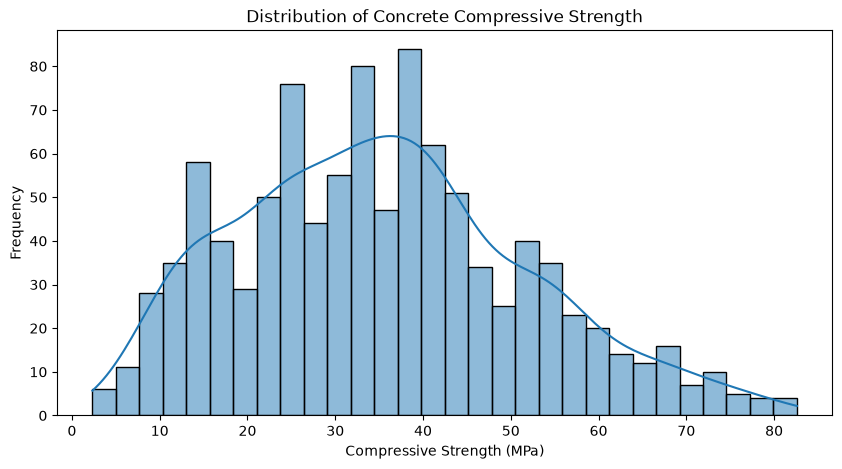

In [83]:
plt.figure(figsize=(10, 5))

sns.histplot(
    data=df_clean,
    x='compressive_strength_mpa',
    bins=30,
    kde=True
)

plt.title('Distribution of Concrete Compressive Strength')
plt.xlabel('Compressive Strength (MPa)')
plt.ylabel('Frequency')

plt.show()

# OBSERVATIONS

### EDA 1: Distribution of Concrete Compressive Strength

#### The histogram illustrates the distribution of compressive strength across the concrete dataset.

#### The majority of observations are concentrated between approximately 20 and 50 MPa, with the highest frequency occurring around 30–40 MPa.

#### The distribution exhibits a slight positive (right) skew, as the tail extends towards higher compressive strength values.

#### The descriptive statistics support this observation, with a mean strength of 35.82 MPa and a median of 34.45 MPa.

#### The strength values range from 2.33 MPa to 82.60 MPa, indicating considerable variation across the concrete mixtures.

### **Conclusion:** Concrete compressive strength is not perfectly normally distributed and exhibits a slight right-skewed distribution.

## EDA 2 : Correration Analysis

In [84]:
# Calculate correlation with compressive strength

correlation = df_clean.corr()

strength_correlation = (
    correlation['compressive_strength_mpa']
    .drop('compressive_strength_mpa')
    .sort_values(ascending=False)
)

print(strength_correlation)

total_binder                0.598103
log_age                     0.559853
cement_kg_m3                0.488283
superplasticizer_kg_m3      0.344209
age_days                    0.337367
blast_furnace_slag_kg_m3    0.103374
fly_ash_kg_m3              -0.080648
coarse_aggregate_kg_m3     -0.144717
fine_aggregate_kg_m3       -0.186448
water_kg_m3                -0.269624
water_cement_ratio         -0.489401
Name: compressive_strength_mpa, dtype: float64


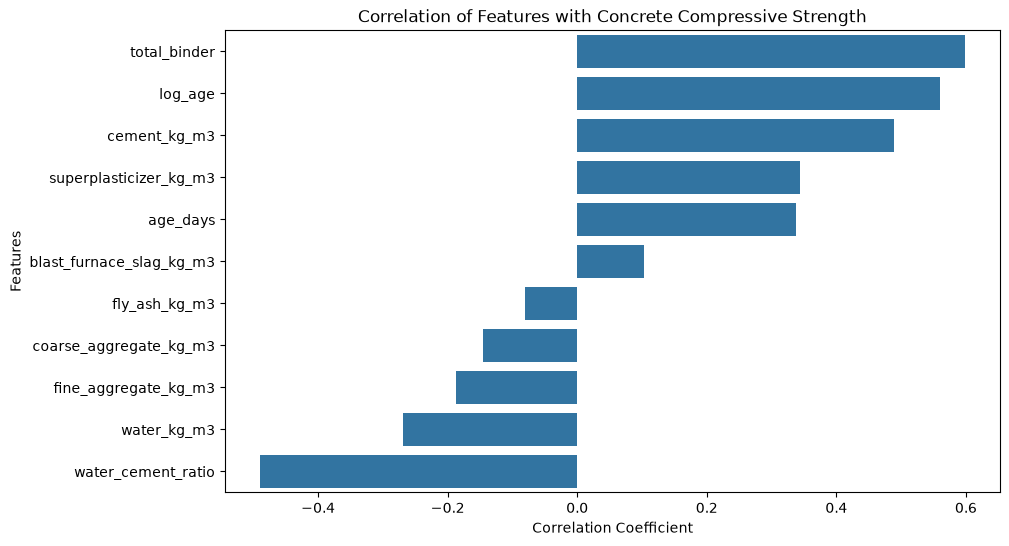

In [85]:
plt.figure(figsize=(10, 6))

sns.barplot(
    x=strength_correlation.values,
    y=strength_correlation.index
)

plt.title('Correlation of Features with Concrete Compressive Strength')
plt.xlabel('Correlation Coefficient')
plt.ylabel('Features')

plt.show()

# OBSERVATIONS

### EDA 2: Correlation Analysis

#### Pearson correlation analysis was conducted to investigate the relationships between concrete mix variables and compressive strength.

#### The results showed that total binder had the strongest positive correlation with compressive strength (0.598), followed by log age (0.560) and cement (0.488).

#### Water-to-cement ratio showed a moderate negative correlation (-0.489), indicating that higher water-to-cement ratios tend to be associated with lower concrete strength.

#### Water quantity also showed a negative correlation (-0.270).

#### Among the original individual ingredients, cement demonstrated the strongest positive correlation with compressive strength.

#### The logarithmic transformation of curing age produced a stronger correlation (0.560) than the original age variable (0.337), supporting the use of feature engineering to represent nonlinear curing behaviour.

### **Conclusion:** Total binder, curing age and water-to-cement ratio appear to be important variables for understanding concrete strength. These relationships will be investigated further during model development.

## EDA 3 : Curing age versus concrete strength

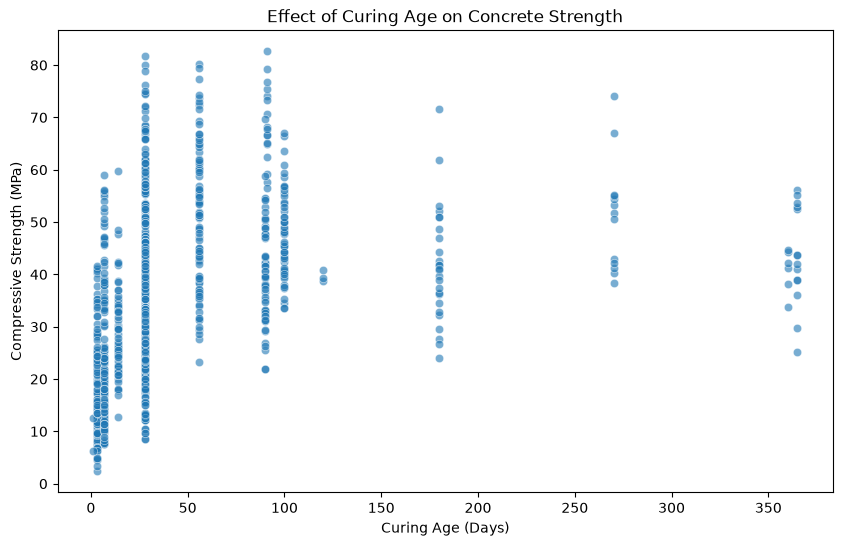

In [86]:
plt.figure(figsize=(10, 6))

sns.scatterplot(
    data=df_clean,
    x='age_days',
    y='compressive_strength_mpa',
    alpha=0.6
)

plt.title('Effect of Curing Age on Concrete Strength')
plt.xlabel('Curing Age (Days)')
plt.ylabel('Compressive Strength (MPa)')

plt.show()

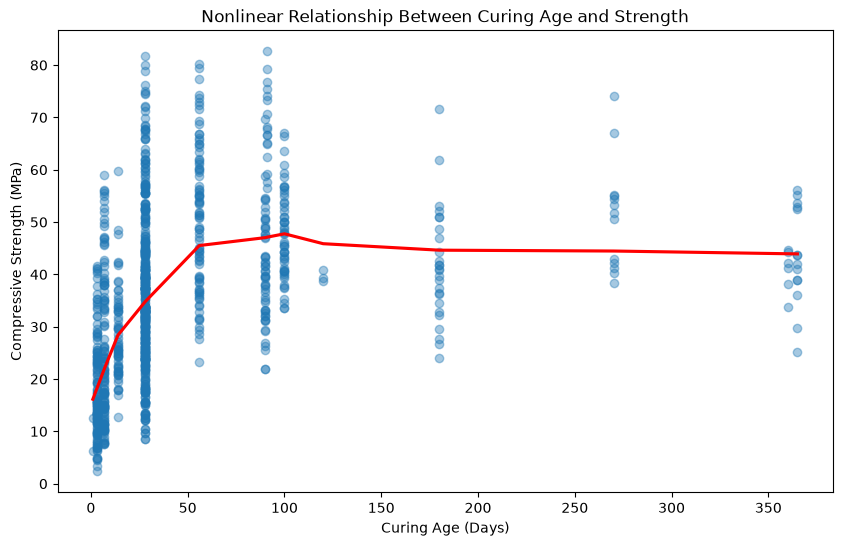

In [87]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='age_days',
    y='compressive_strength_mpa',
    lowess=True,
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Nonlinear Relationship Between Curing Age and Strength')
plt.xlabel('Curing Age (Days)')
plt.ylabel('Compressive Strength (MPa)')

plt.show()

### EDA 3: Relationship Between Curing Age and Concrete Compressive Strength

#### Scatterplot analysis and LOWESS smoothing were used to investigate the relationship between curing age and concrete compressive strength.

#### The results indicate that concrete strength generally increases rapidly during the early curing period. However, the rate of strength development becomes slower as curing age increases.

#### The LOWESS trend line demonstrates a nonlinear relationship rather than a straight-line pattern.

#### There is also considerable variation in strength measurements at the same curing age, indicating that other factors, including ingredient quantities and mix proportions, influence compressive strength.

#### The trend at older curing ages should be interpreted cautiously because fewer observations are available in those age ranges.

### **Conclusion:** Curing age has a nonlinear relationship with concrete compressive strength. This supports the use of the logarithmic age feature and the investigation of nonlinear machine learning models such as Random Forest.

### Water to cement ratio vs Strength

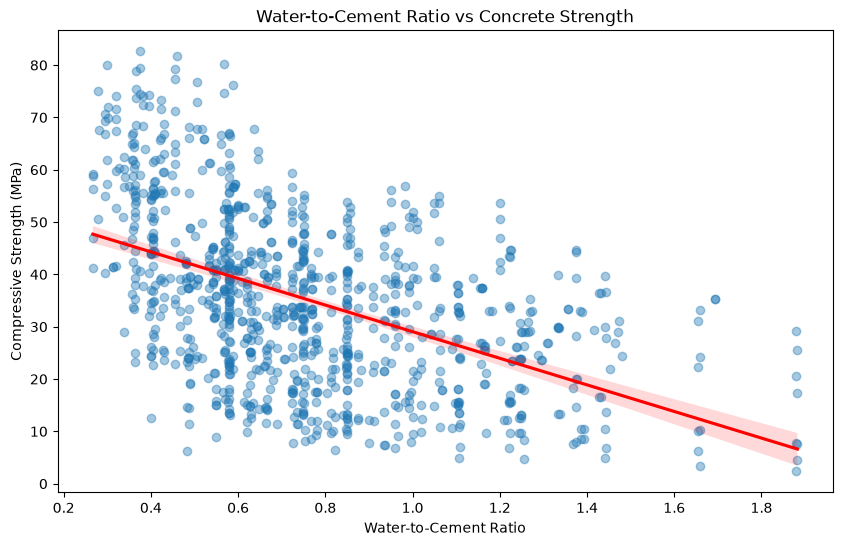

In [88]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='water_cement_ratio',
    y='compressive_strength_mpa',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Water-to-Cement Ratio vs Concrete Strength')
plt.xlabel('Water-to-Cement Ratio')
plt.ylabel('Compressive Strength (MPa)')

plt.show()

### Water VS Strength

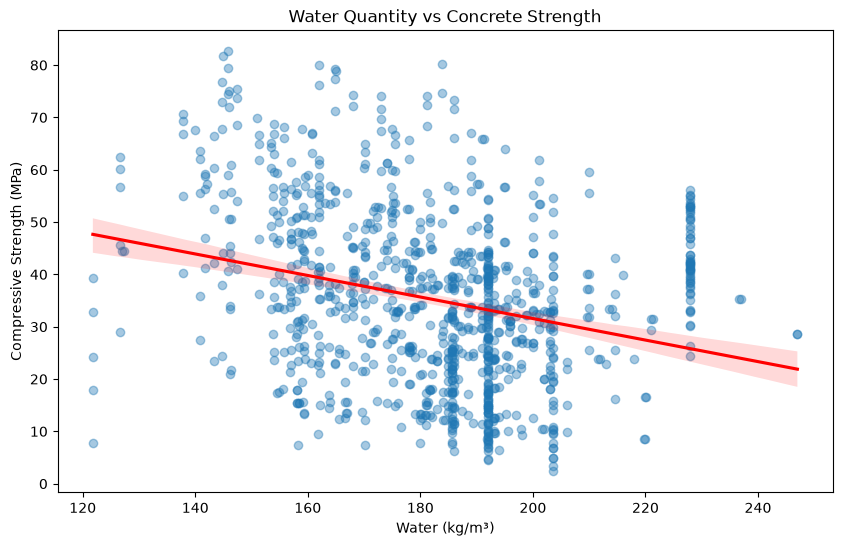

In [89]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='water_kg_m3',
    y='compressive_strength_mpa',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Water Quantity vs Concrete Strength')
plt.xlabel('Water (kg/m³)')
plt.ylabel('Compressive Strength (MPa)')

plt.show()

### Cement vs Strength

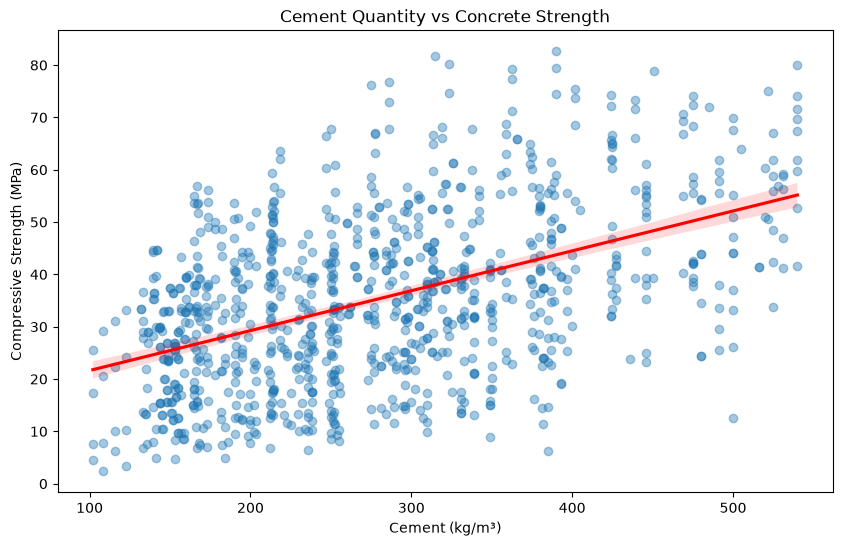

In [90]:
plt.figure(figsize=(10, 6))

sns.regplot(
    data=df_clean,
    x='cement_kg_m3',
    y='compressive_strength_mpa',
    scatter_kws={'alpha': 0.4},
    line_kws={'color': 'red'}
)

plt.title('Cement Quantity vs Concrete Strength')
plt.xlabel('Cement (kg/m³)')
plt.ylabel('Compressive Strength (MPa)')

plt.show()

# OBSERVATIONS

#### Water, Cement and Water-to-Cement Ratio vs Concrete Strength
#### The three graphs reveal that cement quantity has a positive relationship with concrete strength (correlation: +0.488), while water quantity has a negative relationship (-0.270). The water-to-cement ratio shows a stronger negative relationship (-0.489) than water quantity alone. This suggests that the proportion of water relative to cement is an important factor in determining concrete strength.

#### Conclusion: Water-to-cement ratio provides a stronger linear association with concrete strength than either water or cement considered individually, although its correlation is almost identical in magnitude to cement's.

# Machine Learning – Model Development

In [91]:
# IMPORT MACHINE LEARNING LIBRARIES

from sklearn.model_selection import GroupShuffleSplit
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

print("Machine learning libraries imported successfully!")

Machine learning libraries imported successfully!


In [92]:
# DEFINE FEATURES AND TARGET

X = df_clean.drop(
    columns=['compressive_strength_mpa']
)

y = df_clean['compressive_strength_mpa']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (1005, 11)
Target shape: (1005,)


#### Split dataset into training and test sets

##### We will use an 80:20 split.
##### - 80% for training.
##### - 20% for testing.

In [93]:
# STEP 2: PREPARE GROUPS FOR DATA SPLITTING

original_features = [
    'cement_kg_m3',
    'blast_furnace_slag_kg_m3',
    'fly_ash_kg_m3',
    'water_kg_m3',
    'superplasticizer_kg_m3',
    'coarse_aggregate_kg_m3',
    'fine_aggregate_kg_m3',
    'age_days'
]

groups = pd.MultiIndex.from_frame(
    df_clean[original_features]
).factorize()[0]

print("Number of unique input combinations:", len(np.unique(groups)))

Number of unique input combinations: 992


In [94]:
# STEP 3: SPLIT DATA INTO TRAINING AND TESTING SETS

splitter = GroupShuffleSplit(
    n_splits=1,
    test_size=0.2,
    random_state=42
)

train_idx, test_idx = next(
    splitter.split(X, y, groups=groups)
)

X_train = X.iloc[train_idx]
X_test = X.iloc[test_idx]

y_train = y.iloc[train_idx]
y_test = y.iloc[test_idx]

print("Training features:", X_train.shape)
print("Testing features:", X_test.shape)

print("Training target:", y_train.shape)
print("Testing target:", y_test.shape)

Training features: (800, 11)
Testing features: (205, 11)
Training target: (800,)
Testing target: (205,)


#### Mean Baseline model

In [95]:
from sklearn.dummy import DummyRegressor

In [96]:
baseline_model = DummyRegressor(strategy='mean')

baseline_model.fit(X_train, y_train)

baseline_predictions = baseline_model.predict(X_test)

print("Baseline model trained successfully!")

print(baseline_predictions[:10])


Baseline model trained successfully!
[35.08745 35.08745 35.08745 35.08745 35.08745 35.08745 35.08745 35.08745
 35.08745 35.08745]


#### Training Linear Regression model

In [97]:
linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_predictions = linear_model.predict(X_test)

print("Linear Regression model trained successfully!")

print(linear_predictions[:10])

Linear Regression model trained successfully!
[39.21250475 42.78677235 40.49547138 23.37171273 37.65435406 46.05216111
 46.33083144 15.72527101 35.18094447 39.26754377]


#### Training Random Forest model

In [98]:
rf_model = RandomForestRegressor(
    n_estimators=300,
    random_state=42,
    min_samples_leaf=2,
    n_jobs=-1
)

rf_model.fit(X_train, y_train)

rf_predictions = rf_model.predict(X_test)

print("Random Forest model trained successfully!")

print(rf_predictions[:10])

Random Forest model trained successfully!
[41.16629413 39.81990651 52.94526534 30.40594877 52.48553091 38.05692308
 41.69666291 13.25243504 38.84446798 51.78772721]


In [99]:
models = {
    'Mean Baseline': baseline_predictions,
    'Linear Regression': linear_predictions,
    'Random Forest': rf_predictions
}

results = []

for model_name, predictions in models.items():

    mae = mean_absolute_error(y_test, predictions)

    rmse = np.sqrt(mean_squared_error(y_test, predictions))

    r2 = r2_score(y_test, predictions)

    results.append({
        'Model': model_name,
        'MAE': mae,
        'RMSE': rmse,
        'R2 Score': r2
    })

results_df = pd.DataFrame(results)

results_df

,Model,MAE,RMSE,R2 Score
0,Mean Baseline,12.320330,15.237314,-0.002755
1,Linear Regression,5.327660,6.787470,0.801027
2,Random Forest,3.490084,4.551296,0.910536


## Model Performance Comparison

#### Three regression models were evaluated using the same training and testing split: Mean Baseline, Linear Regression and Random Forest.

#### The Mean Baseline achieved an MAE of 12.32 MPa, RMSE of 15.24 MPa and R² of -0.003, demonstrating that a simple average prediction provides poor predictive performance.

#### Linear Regression performed considerably better, achieving an MAE of 5.33 MPa, RMSE of 6.79 MPa and R² of 0.801.

#### Random Forest achieved the best performance, with an MAE of 3.49 MPa, RMSE of 4.55 MPa and R² of 0.911. This indicates that it explains approximately 91.1% of the variation in compressive strength in the test dataset.

#### Random Forest was therefore selected as the preferred model because it achieved the lowest prediction errors and highest R² score among the three models.

In [100]:
prediction_analysis = pd.DataFrame({
    'Actual_Strength': y_test,
    'Predicted_Strength': rf_predictions
}, index=y_test.index)

prediction_analysis['Absolute_Error'] = abs(
    prediction_analysis['Actual_Strength'] -
    prediction_analysis['Predicted_Strength']
)

worst_predictions = prediction_analysis.sort_values(
    by='Absolute_Error',
    ascending=False
)

worst_predictions.head(10)

,Actual_Strength,Predicted_Strength,Absolute_Error
153,80.20,65.293845,14.906155
828,74.99,61.453933,13.536067
518,23.25,35.739516,12.489516
235,17.84,29.938949,12.098949
477,23.35,34.703713,11.353713
573,38.70,49.918170,11.218170
356,63.14,52.198850,10.941150
384,41.37,52.100855,10.730855
479,38.02,48.358909,10.338909
490,34.77,24.827628,9.942372


#### Investigate the concrete mixes

In [101]:
worst_mix_details = df_clean.loc[
    worst_predictions.head(10).index
].copy()

worst_mix_details['Predicted_Strength'] = (
    worst_predictions.loc[
        worst_mix_details.index,
        'Predicted_Strength'
    ]
)

worst_mix_details['Absolute_Error'] = (
    worst_predictions.loc[
        worst_mix_details.index,
        'Absolute_Error'
    ]
)

worst_mix_details[
    original_features +
    ['water_cement_ratio', 'total_binder',
     'compressive_strength_mpa',
     'Predicted_Strength', 'Absolute_Error']
]

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,age_days,water_cement_ratio,total_binder,compressive_strength_mpa,Predicted_Strength,Absolute_Error
153,323.7,282.8,0.0,183.8,10.3,942.7,659.9,56,0.567810,606.5,80.20,65.293845,14.906155
828,522.0,0.0,0.0,146.0,0.0,896.0,896.0,28,0.279693,522.0,74.99,61.453933,13.536067
518,202.0,11.0,141.0,206.0,1.7,942.0,801.0,56,1.019802,354.0,23.25,35.739516,12.489516
235,213.8,98.1,24.5,181.7,6.7,1066.0,785.5,14,0.849860,336.4,17.84,29.938949,12.098949
477,446.0,24.0,79.0,162.0,11.6,967.0,712.0,3,0.363229,549.0,23.35,34.703713,11.353713
573,316.1,210.7,0.0,185.7,0.0,977.0,689.3,28,0.587472,526.8,38.70,49.918170,11.218170
356,277.2,97.8,24.5,160.7,11.2,1061.7,782.5,28,0.579726,399.5,63.14,52.198850,10.941150
384,516.0,0.0,0.0,162.0,8.2,801.0,802.0,28,0.313953,516.0,41.37,52.100855,10.730855
479,446.0,24.0,79.0,162.0,11.6,967.0,712.0,7,0.363229,549.0,38.02,48.358909,10.338909
490,387.0,20.0,94.0,157.0,11.6,938.0,845.0,3,0.405685,501.0,34.77,24.827628,9.942372


### Investigation of the worst model prediction

#### The 10 largest prediction errors from the Random Forest model were investigated to understand where the model struggled.

#### The model showed a tendency to underestimate some high-strength concrete samples, particularly mixes with high total binder content. For example, one mix with a total binder content of 606.5 kg/m³ and a curing age of 56 days had an actual compressive strength of 80.20 MPa, compared with a predicted strength of 65.29 MPa.

#### The model also overestimated the strength of some lower-strength mixes. One observation with a water-cement ratio of 1.02 had an actual strength of 23.25 MPa, while the model predicted 35.74 MPa.

#### Some of the largest errors also occurred in samples with short curing periods of 3–7 days, suggesting that early-age strength prediction may be challenging.

#### Overall, the investigation indicates that although Random Forest achieved strong overall performance, it was less accurate for certain unusual mix compositions and strength levels. These findings highlight the importance of examining individual prediction errors rather than relying solely on aggregate performance metrics.

### Actual Vs Predicted scatter plots

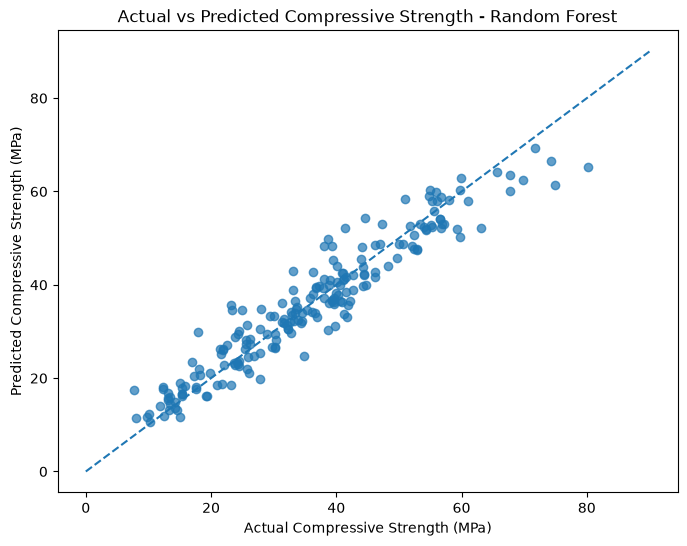

In [102]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 6))

plt.scatter(y_test, rf_predictions, alpha=0.7)

plt.plot(
    [0, 90],
    [0, 90],
    linestyle='--'
)

plt.xlabel('Actual Compressive Strength (MPa)')
plt.ylabel('Predicted Compressive Strength (MPa)')
plt.title('Actual vs Predicted Compressive Strength - Random Forest')

plt.show()

## OBSERVATIONS

### Actual vs Predicted Strength Analysis

#### The actual-versus-predicted scatter plot shows a strong agreement between the observed and predicted compressive strength values. Most observations are distributed relatively close to the 45-degree reference line, indicating good predictive performance.

#### However, some deviations are visible. The model tends to underestimate certain high-strength concrete samples, particularly those with actual strengths above approximately 65 MPa. Some lower-strength observations are also overestimated.

#### These findings are consistent with the model's R² score of 0.911 and RMSE of 4.55 MPa. Overall, the Random Forest model demonstrates strong predictive capability, although prediction accuracy varies across different strength levels.

### Candidate concrete mixes

In [103]:
# Original ingredient columns
ingredient_columns = [
    'cement_kg_m3',
    'blast_furnace_slag_kg_m3',
    'fly_ash_kg_m3',
    'water_kg_m3',
    'superplasticizer_kg_m3',
    'coarse_aggregate_kg_m3',
    'fine_aggregate_kg_m3'
]

# Use recipes from the training data only
candidate_mixes = X_train[ingredient_columns].drop_duplicates().copy()

# Fix curing age at 28 days
candidate_mixes['age_days'] = 28

# Recalculate engineered features
candidate_mixes['water_cement_ratio'] = (
    candidate_mixes['water_kg_m3'] /
    candidate_mixes['cement_kg_m3']
)

candidate_mixes['total_binder'] = (
    candidate_mixes['cement_kg_m3'] +
    candidate_mixes['blast_furnace_slag_kg_m3'] +
    candidate_mixes['fly_ash_kg_m3']
)

candidate_mixes['log_age'] = np.log1p(
    candidate_mixes['age_days']
)

print("Number of candidate recipes:", len(candidate_mixes))
print("Curing age:", candidate_mixes['age_days'].unique())
print("Candidate features:", candidate_mixes.shape[1])

Number of candidate recipes: 374
Curing age: [28]
Candidate features: 11


### Predicting 28 days Strength

In [104]:
# Predict compressive strength for all candidate mixes
candidate_mixes['predicted_strength_mpa'] = rf_model.predict(
    candidate_mixes[X_train.columns]
)

print("Predictions completed!")

Predictions completed!


In [105]:
candidate_mixes[
    ingredient_columns + ['predicted_strength_mpa']
].head(10)

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,predicted_strength_mpa
0,540.0,0.0,0.0,162.0,2.5,1040.0,676.0,69.790666
1,540.0,0.0,0.0,162.0,2.5,1055.0,676.0,67.714798
2,332.5,142.5,0.0,228.0,0.0,932.0,594.0,38.844468
4,198.6,132.4,0.0,192.0,0.0,978.4,825.5,28.148682
5,266.0,114.0,0.0,228.0,0.0,932.0,670.0,42.769636
6,380.0,95.0,0.0,228.0,0.0,932.0,594.0,37.362580
9,475.0,0.0,0.0,228.0,0.0,932.0,594.0,37.962592
12,427.5,47.5,0.0,228.0,0.0,932.0,594.0,37.812344
13,190.0,190.0,0.0,228.0,0.0,932.0,670.0,38.232990
14,304.0,76.0,0.0,228.0,0.0,932.0,670.0,42.997077


In [106]:
# Keep recipes predicted to achieve at least 40 MPa
qualifying_mixes = candidate_mixes[
    candidate_mixes['predicted_strength_mpa'] >= 40
].copy()

# Sort by lowest cement usage first
qualifying_mixes = qualifying_mixes.sort_values(
    by=['cement_kg_m3', 'predicted_strength_mpa'],
    ascending=[True, False]
)

print("Number of qualifying recipes:", len(qualifying_mixes))

qualifying_mixes[
    ingredient_columns + ['water_cement_ratio',
                          'predicted_strength_mpa']
].head(10)

Number of qualifying recipes: 116


,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,water_cement_ratio,predicted_strength_mpa
1000,141.9,166.6,129.7,173.5,10.9,882.6,785.3,1.222692,41.494809
843,142.0,167.0,130.0,174.0,11.0,883.0,785.0,1.225352,41.012534
420,165.0,128.5,132.1,175.1,8.1,1005.8,746.6,1.061212,42.344928
409,167.4,129.9,128.6,175.5,7.8,1006.3,746.6,1.048387,40.662118
395,200.0,200.0,0.0,190.0,0.0,1145.0,660.0,0.950000,42.470187
349,213.5,0.0,174.2,154.6,11.7,1052.3,775.5,0.724122,44.597943
416,213.5,0.0,174.2,159.2,11.7,1043.6,771.9,0.745667,43.111936
345,213.7,0.0,174.7,154.8,10.2,1053.5,776.4,0.724380,44.089546
364,214.9,53.8,121.9,155.6,9.6,1014.3,780.6,0.724058,47.280891
359,218.2,54.6,123.8,140.8,11.9,1075.7,792.7,0.645280,52.161911


In [107]:
# Calculate water-to-binder ratio
qualifying_mixes['water_binder_ratio'] = (
    qualifying_mixes['water_kg_m3'] /
    qualifying_mixes['total_binder']
)

# Calculate strength margin above the requirement
qualifying_mixes['strength_margin'] = (
    qualifying_mixes['predicted_strength_mpa'] - 40
)

# Display the 10 lowest-cement qualifying recipes
qualifying_mixes[
    ingredient_columns +
    ['total_binder',
     'water_cement_ratio',
     'water_binder_ratio',
     'predicted_strength_mpa',
     'strength_margin']
].head(10)

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,total_binder,water_cement_ratio,water_binder_ratio,predicted_strength_mpa,strength_margin
1000,141.9,166.6,129.7,173.5,10.9,882.6,785.3,438.2,1.222692,0.395938,41.494809,1.494809
843,142.0,167.0,130.0,174.0,11.0,883.0,785.0,439.0,1.225352,0.396355,41.012534,1.012534
420,165.0,128.5,132.1,175.1,8.1,1005.8,746.6,425.6,1.061212,0.411419,42.344928,2.344928
409,167.4,129.9,128.6,175.5,7.8,1006.3,746.6,425.9,1.048387,0.412069,40.662118,0.662118
395,200.0,200.0,0.0,190.0,0.0,1145.0,660.0,400.0,0.950000,0.475000,42.470187,2.470187
349,213.5,0.0,174.2,154.6,11.7,1052.3,775.5,387.7,0.724122,0.398762,44.597943,4.597943
416,213.5,0.0,174.2,159.2,11.7,1043.6,771.9,387.7,0.745667,0.410627,43.111936,3.111936
345,213.7,0.0,174.7,154.8,10.2,1053.5,776.4,388.4,0.724380,0.398558,44.089546,4.089546
364,214.9,53.8,121.9,155.6,9.6,1014.3,780.6,390.6,0.724058,0.398361,47.280891,7.280891
359,218.2,54.6,123.8,140.8,11.9,1075.7,792.7,396.6,0.645280,0.355018,52.161911,12.161911


### Safety Margin?

In [108]:
# Calculate test-set prediction errors
test_errors = y_test - rf_predictions

# Keep only cases where the model underestimated strength
underprediction_errors = test_errors[test_errors > 0]

# Calculate the 90th percentile underprediction error
safety_margin = np.percentile(underprediction_errors, 90)

print("90th percentile underprediction:", round(safety_margin, 2), "MPa")

90th percentile underprediction: 7.61 MPa


In [109]:
# Apply the adjusted strength threshold
safer_mixes = qualifying_mixes[
    qualifying_mixes['predicted_strength_mpa'] >= 47.61
].copy()

# Rank by lowest cement quantity
safer_mixes = safer_mixes.sort_values(
    by='cement_kg_m3',
    ascending=True
)

print("Number of recipes meeting adjusted threshold:", len(safer_mixes))

safer_mixes[
    ingredient_columns +
    ['predicted_strength_mpa', 'water_binder_ratio']
].head(10)

Number of recipes meeting adjusted threshold: 67


,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,predicted_strength_mpa,water_binder_ratio
359,218.2,54.6,123.8,140.8,11.9,1075.7,792.7,52.161911,0.355018
329,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,49.345795,0.385319
400,250.0,180.0,95.0,159.0,9.5,860.0,800.0,61.559321,0.302857
404,275.0,180.0,120.0,162.0,10.4,830.0,765.0,68.005405,0.281739
336,275.1,0.0,121.4,159.5,9.9,1053.6,777.5,49.793783,0.402270
354,277.2,97.8,24.5,160.7,11.2,1061.7,782.5,52.198850,0.402253
402,285.0,190.0,0.0,163.0,7.6,1031.0,685.0,53.184201,0.343158
87,286.3,200.9,0.0,144.7,11.2,1004.6,803.7,60.057363,0.297003
1001,297.8,137.2,106.9,201.3,6.0,878.4,655.3,50.677321,0.371471
844,298.0,137.0,107.0,201.0,6.0,878.0,655.0,50.248735,0.370849


In [110]:
print("Total qualifying safer recipes:", len(safer_mixes))

print("Lowest cement quantity:",
      safer_mixes['cement_kg_m3'].min())

print("Highest predicted strength:",
      safer_mixes['predicted_strength_mpa'].max())

Total qualifying safer recipes: 67
Lowest cement quantity: 218.2
Highest predicted strength: 74.60794146825401


### Cost of all 67 Recipes

In [111]:
ingredient_prices = {
    'cement_kg_m3': 0.15,
    'blast_furnace_slag_kg_m3': 0.07,
    'fly_ash_kg_m3': 0.05,
    'water_kg_m3': 0.002,
    'superplasticizer_kg_m3': 1.20,
    'coarse_aggregate_kg_m3': 0.025,
    'fine_aggregate_kg_m3': 0.030
}

print("Ingredient prices successfully defined.")

Ingredient prices successfully defined.


In [112]:
# Calculate estimated material cost per cubic metre

safer_mixes['estimated_cost_gbp_m3'] = sum(
    safer_mixes[column] * price
    for column, price in ingredient_prices.items()
)

# Sort from cheapest to most expensive
cost_optimized_mixes = safer_mixes.sort_values(
    by='estimated_cost_gbp_m3',
    ascending=True
).copy()

print("Cost calculation completed!")
print("Recipes evaluated:", len(cost_optimized_mixes))

Cost calculation completed!
Recipes evaluated: 67


In [113]:
cost_optimized_mixes[
    ingredient_columns +
    ['predicted_strength_mpa', 'estimated_cost_gbp_m3']
].head(10).round(2)

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,predicted_strength_mpa,estimated_cost_gbp_m3
359,218.2,54.6,123.8,140.8,11.9,1075.7,792.7,52.16,107.98
1001,297.8,137.2,106.9,201.3,6.0,878.4,655.3,50.68,108.84
844,298.0,137.0,107.0,201.0,6.0,878.0,655.0,50.25,108.84
329,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,49.35,109.16
336,275.1,0.0,121.4,159.5,9.9,1053.6,777.5,49.79,109.20
394,405.0,0.0,0.0,175.0,0.0,1120.0,695.0,52.79,109.95
1002,321.3,164.2,0.0,190.5,4.6,870.0,774.0,53.89,110.56
402,285.0,190.0,0.0,163.0,7.6,1031.0,685.0,53.18,111.82
400,250.0,180.0,95.0,159.0,9.5,860.0,800.0,61.56,112.07
354,277.2,97.8,24.5,160.7,11.2,1061.7,782.5,52.20,113.43


### Safety Margin Calculation

In [114]:
# Calculate cases where the model overpredicted strength
overprediction_errors = rf_predictions - y_test

overprediction_errors = overprediction_errors[
    overprediction_errors > 0
]

# Calculate the 90th percentile overprediction
safety_margin_corrected = np.percentile(
    overprediction_errors, 90
)

print(
    "Corrected 90th percentile overprediction:",
    round(safety_margin_corrected, 2),
    "MPa"
)

print(
    "Adjusted screening threshold:",
    round(40 + safety_margin_corrected, 2),
    "MPa"
)

Corrected 90th percentile overprediction: 8.9 MPa
Adjusted screening threshold: 48.9 MPa


#### Recalculate the Final Recipe

In [115]:
# Apply corrected strength threshold
final_mixes = safer_mixes[
    safer_mixes['predicted_strength_mpa'] >= 48.9
].copy()

# Calculate estimated material cost
final_mixes['estimated_cost_gbp_m3'] = sum(
    final_mixes[col] * price
    for col, price in ingredient_prices.items()
)

# Sort by lowest estimated cost
final_mixes = final_mixes.sort_values(
    'estimated_cost_gbp_m3'
)

print("Recipes meeting corrected threshold:", len(final_mixes))

final_mixes[
    ingredient_columns +
    ['predicted_strength_mpa', 'estimated_cost_gbp_m3']
].head(5).round(2)

Recipes meeting corrected threshold: 64


,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,predicted_strength_mpa,estimated_cost_gbp_m3
359,218.2,54.6,123.8,140.8,11.9,1075.7,792.7,52.16,107.98
1001,297.8,137.2,106.9,201.3,6.0,878.4,655.3,50.68,108.84
844,298.0,137.0,107.0,201.0,6.0,878.0,655.0,50.25,108.84
329,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,49.35,109.16
336,275.1,0.0,121.4,159.5,9.9,1053.6,777.5,49.79,109.20


## Observations

### Cost Optimisation Recommendation

#### Using illustrative ingredient prices, 67 candidate recipes were initially screened. A revised strength threshold of 48.9 MPa was then applied to account for observed model overprediction errors.

#### The lowest-cost qualifying candidate was recipe 359, with an estimated material cost of £107.98 per m³ and a predicted 28-day compressive strength of 52.16 MPa.

#### The proposed mix contains 218.2 kg/m³ of cement, alongside supplementary cementitious materials including blast furnace slag and fly ash.

#### This is a preliminary model-based recommendation. Ingredient prices are illustrative, and the proposed mix must undergo laboratory testing at 28 days before approval. The estimated cost should not be interpreted as a verified commercial saving

## Building ML Pipeline

In [116]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import FunctionTransformer
import joblib

print("Pipeline libraries imported successfully!")

Pipeline libraries imported successfully!


In [117]:
def engineer_concrete_features(data):

    data = data.copy()

    data['water_cement_ratio'] = (
        data['water_kg_m3'] / data['cement_kg_m3']
    )

    data['total_binder'] = (
        data['cement_kg_m3']
        + data['blast_furnace_slag_kg_m3']
        + data['fly_ash_kg_m3']
    )

    data['log_age'] = np.log1p(data['age_days'])

    return data


print("Feature engineering function created successfully!")

Feature engineering function created successfully!


### Feature Engineering to Random Forest

In [118]:
concrete_pipeline = Pipeline([
    ('feature_engineering',
     FunctionTransformer(engineer_concrete_features,
                         validate=False)),

    ('random_forest', rf_model)
])

print("Concrete prediction pipeline created successfully!")

Concrete prediction pipeline created successfully!


In [119]:
# Select one test recipe using the original 8 features
test_recipe = X_test[original_features].iloc[[0]]

# Predict using the new pipeline
pipeline_prediction = concrete_pipeline.predict(test_recipe)

# Predict using the original Random Forest
original_prediction = rf_model.predict(X_test.iloc[[0]])

print("Pipeline prediction:", pipeline_prediction[0])
print("Original model prediction:", original_prediction[0])

print(
    "Predictions match:",
    np.isclose(pipeline_prediction[0], original_prediction[0])
)

Pipeline prediction: 41.166294126984184
Original model prediction: 41.166294126984155
Predictions match: True


In [120]:
joblib.dump(concrete_pipeline, 'meridian_concrete_pipeline.pkl')

print("Pipeline saved successfully!")

Pipeline saved successfully!


In [121]:
from sklearn import set_config
from IPython.display import display

# Enable visual pipeline display
set_config(display='diagram')

# Display our concrete prediction pipeline
display(concrete_pipeline)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('feature_engineering', ...), ('random_forest', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function eng...001ED19642090>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, default=

## Meridian Concrete Strength Prediction Pipeline

### **Input:** Seven concrete ingredient quantities and curing age (8 original features).

### **Stage 1 – Feature Engineering**
### - Water-to-cement ratio
### - Total binder
### - Logarithm of curing age

### **Stage 2 – Random Forest Regressor**
### - Trained model with 300 decision trees.
### - Processes all 11 input features.

### **Output:** Predicted 28-day compressive strength (MPa).

### **Purpose:** Automates feature engineering and concrete strength prediction for new concrete recipes.

### Loading the saved Pipeline

In [122]:
# Load the saved machine learning pipeline
loaded_pipeline = joblib.load('meridian_concrete_pipeline.pkl')

print("Saved pipeline loaded successfully!")

Saved pipeline loaded successfully!


In [123]:
# Test prediction using the loaded pipeline
test_prediction = loaded_pipeline.predict(test_recipe)

print("Predicted compressive strength:", round(test_prediction[0], 2), "MPa")

Predicted compressive strength: 41.17 MPa


## Building an interactive Demo

In [140]:
import gradio as gr
print(gr.__version__)

6.32.0


In [141]:
import os

print(os.path.exists("meridian_concrete_pipeline.pkl"))

True


### Loading saved model

In [142]:
import gradio as gr
import joblib

model = joblib.load("meridian_concrete_pipeline.pkl")

print("Gradio:", gr.__version__)
print("Model loaded successfully!")

Gradio: 6.32.0
Model loaded successfully!


In [143]:
import pandas as pd
import numpy as np

def predict_concrete_strength(
    cement,
    slag,
    fly_ash,
    water,
    superplasticizer,
    coarse_aggregate,
    fine_aggregate,
    age
):
    input_data = pd.DataFrame([{
        'cement_kg_m3': cement,
        'blast_furnace_slag_kg_m3': slag,
        'fly_ash_kg_m3': fly_ash,
        'water_kg_m3': water,
        'superplasticizer_kg_m3': superplasticizer,
        'coarse_aggregate_kg_m3': coarse_aggregate,
        'fine_aggregate_kg_m3': fine_aggregate,
        'age_days': age
    }])

    prediction = model.predict(input_data)[0]

    return round(float(prediction), 2)


print("Prediction function created successfully!")

Prediction function created successfully!


### Testing the prediction function

In [144]:
test_strength = predict_concrete_strength(
    cement=218.2,
    slag=54.6,
    fly_ash=123.8,
    water=140.8,
    superplasticizer=11.9,
    coarse_aggregate=1075.7,
    fine_aggregate=792.7,
    age=28
)

print(f"Predicted compressive strength: {test_strength} MPa")

Predicted compressive strength: 52.16 MPa


### Gradio Interface

In [145]:
demo = gr.Interface(
    fn=predict_concrete_strength,
    inputs=[
        gr.Number(label="Cement (kg/m³)", value=218.2),
        gr.Number(label="Blast Furnace Slag (kg/m³)", value=54.6),
        gr.Number(label="Fly Ash (kg/m³)", value=123.8),
        gr.Number(label="Water (kg/m³)", value=140.8),
        gr.Number(label="Superplasticizer (kg/m³)", value=11.9),
        gr.Number(label="Coarse Aggregate (kg/m³)", value=1075.7),
        gr.Number(label="Fine Aggregate (kg/m³)", value=792.7),
        gr.Number(label="Age (days)", value=28)
    ],
    outputs=gr.Number(label="Predicted Compressive Strength (MPa)"),
    title="Meridian Ready-Mix | Concrete Strength Predictor",
    description=(
        "Enter concrete mix proportions to predict compressive strength. "
        "The model provides an estimate, not laboratory certification."
    ),
    submit_btn="Predict Concrete Strength",
    clear_btn="Reset Inputs"
)

print("Gradio interface created successfully!")

Gradio interface created successfully!


### Launch the Demo

In [146]:
demo.launch(share=True)

* Running on local URL:  http://127.0.0.1:7868

Could not create share link. Please check your internet connection or our status page: https://status.gradio.app.


#### 40 MPA Assessment

In [147]:
def assess_concrete_strength(
    cement, slag, fly_ash, water,
    superplasticizer, coarse_aggregate,
    fine_aggregate, age
):
    strength = predict_concrete_strength(
        cement, slag, fly_ash, water,
        superplasticizer, coarse_aggregate,
        fine_aggregate, age
    )

    if strength >= 40:
        assessment = "Meets the 40 MPa target (model prediction)"
    else:
        assessment = "Below the 40 MPa target (model prediction)"

    return strength, assessment


print(assess_concrete_strength(
    218.2, 54.6, 123.8, 140.8,
    11.9, 1075.7, 792.7, 28
))

(52.16, 'Meets the 40 MPa target (model prediction)')


### Prepare the Optimisation Data

In [148]:
print("Candidate recipes:", len(candidate_mixes))
print("Predicted strength column:",
      'predicted_strength_mpa' in candidate_mixes.columns)

Candidate recipes: 374
Predicted strength column: True


#### Ingredient Prices

In [149]:
ingredient_prices = {
    'cement_kg_m3': 0.15,
    'blast_furnace_slag_kg_m3': 0.07,
    'fly_ash_kg_m3': 0.05,
    'water_kg_m3': 0.002,
    'superplasticizer_kg_m3': 1.20,
    'coarse_aggregate_kg_m3': 0.025,
    'fine_aggregate_kg_m3': 0.030
}

candidate_mixes['estimated_cost_gbp_m3'] = sum(
    candidate_mixes[column] * price
    for column, price in ingredient_prices.items()
)

print("Estimated costs calculated successfully!")

Estimated costs calculated successfully!


#### Cheapest Qualifying Recipe

In [150]:
qualifying = candidate_mixes[
    candidate_mixes['predicted_strength_mpa'] >= 48.9
].sort_values('estimated_cost_gbp_m3')

display(
    qualifying[[
        'cement_kg_m3',
        'blast_furnace_slag_kg_m3',
        'fly_ash_kg_m3',
        'water_kg_m3',
        'superplasticizer_kg_m3',
        'coarse_aggregate_kg_m3',
        'fine_aggregate_kg_m3',
        'predicted_strength_mpa',
        'estimated_cost_gbp_m3'
    ]].head(5).round(2)
)

,cement_kg_m3,blast_furnace_slag_kg_m3,fly_ash_kg_m3,water_kg_m3,superplasticizer_kg_m3,coarse_aggregate_kg_m3,fine_aggregate_kg_m3,predicted_strength_mpa,estimated_cost_gbp_m3
359,218.2,54.6,123.8,140.8,11.9,1075.7,792.7,52.16,107.98
1001,297.8,137.2,106.9,201.3,6.0,878.4,655.3,50.68,108.84
844,298.0,137.0,107.0,201.0,6.0,878.0,655.0,50.25,108.84
329,246.8,0.0,125.1,143.3,12.0,1086.8,800.9,49.35,109.16
336,275.1,0.0,121.4,159.5,9.9,1053.6,777.5,49.79,109.20


#### Optimisation into Gradio

In [151]:
best_mix = qualifying.iloc[0]

recommendation = (
    f"Recommended mix: Recipe {best_mix.name}\n"
    f"Predicted strength: {best_mix['predicted_strength_mpa']:.2f} MPa\n"
    f"Estimated cost: £{best_mix['estimated_cost_gbp_m3']:.2f} per m³\n"
    f"Screening threshold: 48.9 MPa"
)

print(recommendation)

Recommended mix: Recipe 359
Predicted strength: 52.16 MPa
Estimated cost: £107.98 per m³
Screening threshold: 48.9 MPa


#### Final Gradio interface

In [152]:
def complete_prediction(
    cement, slag, fly_ash, water,
    superplasticizer, coarse_aggregate,
    fine_aggregate, age
):
    strength, assessment = assess_concrete_strength(
        cement, slag, fly_ash, water,
        superplasticizer, coarse_aggregate,
        fine_aggregate, age
    )

    recommendation = f"""
LOWEST-COST QUALIFYING CANDIDATE: Recipe {best_mix.name}

Predicted strength: {best_mix['predicted_strength_mpa']:.2f} MPa
Estimated ingredient cost: £{best_mix['estimated_cost_gbp_m3']:.2f}/m³

RECOMMENDED MIX (kg/m³)
Cement: {best_mix['cement_kg_m3']}
Blast furnace slag: {best_mix['blast_furnace_slag_kg_m3']}
Fly ash: {best_mix['fly_ash_kg_m3']}
Water: {best_mix['water_kg_m3']}
Superplasticizer: {best_mix['superplasticizer_kg_m3']}
Coarse aggregate: {best_mix['coarse_aggregate_kg_m3']}
Fine aggregate: {best_mix['fine_aggregate_kg_m3']}

Screening threshold: 48.9 MPa
Prices are illustrative. Laboratory validation is required.
"""

    return strength, assessment, recommendation


demo = gr.Interface(
    fn=complete_prediction,
    inputs=[
        gr.Number(label="Cement (kg/m³)", value=218.2),
        gr.Number(label="Blast Furnace Slag (kg/m³)", value=54.6),
        gr.Number(label="Fly Ash (kg/m³)", value=123.8),
        gr.Number(label="Water (kg/m³)", value=140.8),
        gr.Number(label="Superplasticizer (kg/m³)", value=11.9),
        gr.Number(label="Coarse Aggregate (kg/m³)", value=1075.7),
        gr.Number(label="Fine Aggregate (kg/m³)", value=792.7),
        gr.Number(label="Age (days)", value=28)
    ],
    outputs=[
        gr.Number(label="Predicted Strength (MPa)"),
        gr.Textbox(label="40 MPa Target Assessment"),
        gr.Textbox(label="Cost Optimisation Recommendation", lines=14)
    ],
    title="MERIDIAN READY-MIX",
    description="Concrete Compressive Strength Prediction and Cost Optimisation",
    submit_btn="Analyse Concrete Mix",
    clear_btn="Reset"
)

demo.launch(inline=True, share=False)

* Running on local URL:  http://127.0.0.1:7869
* To create a public link, set `share=True` in `launch()`.


## Final Findings and Key Insights

### The analysis of the Concrete Compressive Strength dataset revealed several important relationships between concrete mix composition, curing age and compressive strength.

### 1. Distribution of Concrete Strength
### The compressive strength values were slightly right-skewed, with a mean of **35.82 MPa** and a median of **34.45 MPa**. This indicates that a smaller number of high-strength concrete samples pull the average above the median. Strength values ranged from approximately 2.33 MPa to 82.60 MPa.

### 2. Most Influential Individual Ingredient
### Cement showed the strongest positive individual correlation with compressive strength among the ingredients, at approximately **0.488**. This suggests that higher cement content is generally associated with higher concrete strength, although strength depends on the combined mix composition.

### 3. Effect of Curing Age
### Concrete strength generally increased as curing age increased. However, the relationship was nonlinear: strength increased more rapidly during earlier curing periods and tended to grow more gradually at later ages. This indicates that a simple straight-line relationship does not fully explain strength development.

### 4. Importance of Water-to-Cement Ratio
### The water-to-cement ratio had a correlation of approximately **-0.489** with compressive strength, indicating that higher ratios were generally associated with lower strength. Its relationship was slightly stronger in absolute terms than cement alone (0.488), demonstrating the importance of considering ingredient proportions rather than individual quantities in isolation.

### 5. Model Performance
### Three regression approaches were compared using the same grouped training and testing split. The mean baseline performed poorly, while Linear Regression achieved an R² of **0.801** and Random Forest achieved an R² of **0.911**.

### Random Forest produced the best results, with an MAE of **3.49 MPa** and RMSE of **4.55 MPa**, demonstrating its ability to capture more complex relationships in the dataset than the linear model.

### 6. Largest Prediction Errors
### The model's largest errors included underprediction of some high-strength concrete samples and overprediction of some lower-strength samples. Some difficult predictions also involved early curing ages. This suggests that the model is less accurate at certain extremes and that prediction errors are not evenly distributed across all concrete mixes.

### 7. Cost Optimisation and Recommended Mix
### The optimisation analysis evaluated 374 observed candidate recipes using illustrative ingredient prices. Recipe 359 was identified as the lowest-cost candidate meeting the conservative predicted-strength screening threshold of 48.9 MPa.

### Its predicted compressive strength was **52.16 MPa**, with an estimated ingredient cost of **£107.98 per cubic metre**. This exceeds the required 40 MPa target by 12.16 MPa.

### The recommendation is based on the available candidate recipes and assumed ingredient prices. Actual supplier quotations, production considerations and laboratory testing are required before commercial adoption.

### Overall Conclusion
### The findings demonstrate that concrete compressive strength is influenced by multiple interacting factors, particularly cement content, water-to-cement ratio and curing age. Random Forest provided the strongest predictive performance among the models evaluated.

### The cost optimisation exercise also demonstrated how machine learning can support more informed concrete mix selection by balancing predicted strength requirements with estimated ingredient costs. The developed Meridian Ready-Mix prototype provides a foundation for data-driven concrete mix evaluation and decision support.